In [1]:
import sys
import os

# Añadir la ruta absoluta a 'src'
project_root = os.path.abspath("..")  # o usa "." si el notebook está en la raíz
src_path = os.path.join(project_root, "src")
if src_path not in sys.path:
    sys.path.append(src_path)

In [2]:
import sys
import os

# Asegura que la carpeta src esté en el path
notebook_dir = os.getcwd()
project_root = os.path.abspath(os.path.join(notebook_dir, ".."))
src_path = os.path.join(project_root, "src")

if src_path not in sys.path:
    sys.path.insert(0, src_path)

print("src added to path:", src_path)


src added to path: h:\Mi unidad\pyCon_2025\Repo\instagram-behavior-analysis\src


In [3]:
from data_loader import load_sent_messages, load_all_instagram_events


df = load_all_instagram_events(user_name="Almu", raw_data_path="../data/raw", inbox_path="../data/raw/inbox")
df.head()


Scanning 20 JSON files...
followers_and_following_followers_1: 873 timestamps extracted
followers_and_following_following: 828 timestamps extracted
followers_and_following_recent_follow_requests: 13 timestamps extracted
followers_and_following_recently_unfollowed_profiles: 3 timestamps extracted
likes_liked_comments: 563 timestamps extracted
likes_liked_posts: 18473 timestamps extracted
ads_and_topics_suggested_profiles_viewed: 324 timestamps extracted
ads_and_topics_videos_watched: 389 timestamps extracted
ads_and_topics_ads_clicked: 3 timestamps extracted
ads_and_topics_ads_viewed: 70 timestamps extracted
ads_and_topics_posts_viewed: 480 timestamps extracted
instagram_ads_and_businesses_advertisers_using_your_activity_or_information: 0 timestamps extracted
story_interactions_avatar_story_reactions: 4 timestamps extracted
story_interactions_countdowns: 5 timestamps extracted
story_interactions_polls: 137 timestamps extracted
story_interactions_questions: 2 timestamps extracted
story_i

,event_type,timestamp
0,followers_and_following_followers_1,2019-08-17 20:23:39
1,followers_and_following_followers_1,2019-08-17 20:23:57
2,followers_and_following_following,2019-08-17 20:24:06
3,followers_and_following_followers_1,2019-08-17 20:24:57
4,followers_and_following_following,2019-08-17 21:51:53


## Distribución de eventos por hora del día
Queremos saber a qué hora del día usas más Instagram:

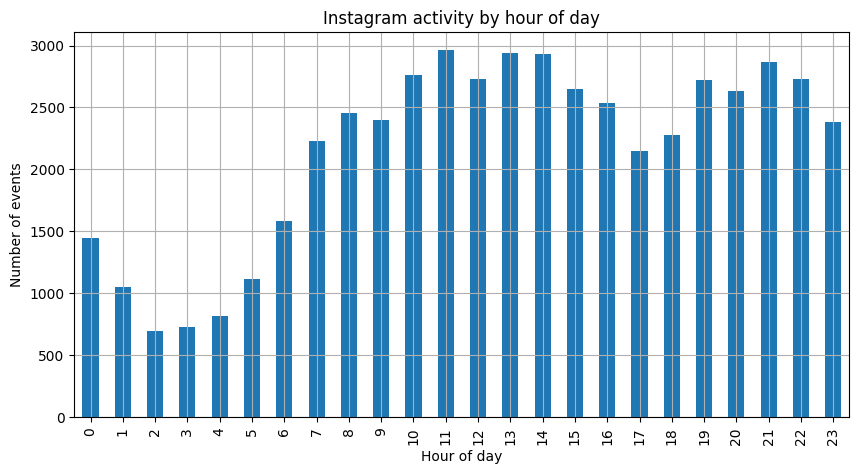

In [3]:
import matplotlib.pyplot as plt

# Añadir columna de hora
df["hour"] = df["timestamp"].dt.hour

# Plot
plt.figure(figsize=(10, 5))
df["hour"].value_counts().sort_index().plot(kind="bar")
plt.title("Instagram activity by hour of day")
plt.xlabel("Hour of day")
plt.ylabel("Number of events")
plt.grid(True)
plt.show()


En el gráfico se observa claramente un patrón bimodal en el uso de Instagram, con dos picos bien definidos de actividad a lo largo del día. El primero ocurre entre las 11:00 y las 14:00, coincidiendo con la franja de media mañana o mediodía, posiblemente durante pausas o descansos. El segundo pico se da entre las 20:00 y las 22:00, en las horas posteriores a la cena, cuando es común relajarse y revisar el móvil. Estos dos momentos contrastan con la baja actividad registrada entre las 2:00 y las 6:00 de la madrugada.

## Cambios a lo largo del tiempo
Creamos un gráfico de actividad a lo largo del tiempo para ver tendencias o anomalías:

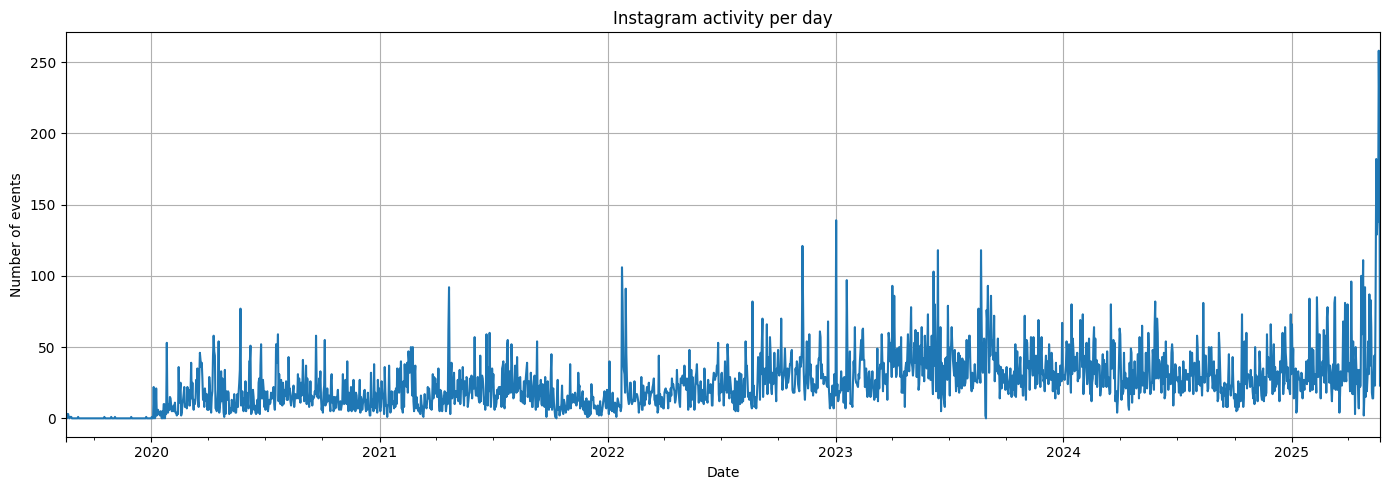

In [4]:
# Re-sample diario
df_daily = df.set_index("timestamp").resample("D").size()

# Plot
plt.figure(figsize=(14, 5))
df_daily.plot()
plt.title("Instagram activity per day")
plt.xlabel("Date")
plt.ylabel("Number of events")
plt.grid(True)
plt.tight_layout()
plt.show()


En el gráfico de actividad diaria de Instagram se aprecia un crecimiento progresivo en el uso desde 2020 hasta 2025, con varios picos que destacan por encima de la tendencia general. Estos picos representan días con una actividad inusualmente alta, que podrían corresponder a eventos personales significativos, vacaciones, rupturas, viajes o simplemente días de mayor conexión emocional o social. Analizar el contexto temporal de esos picos (por ejemplo, qué eventos o interacciones ocurrieron ese día, o si hay patrones de recurrencia semanal o estacional) puede aportar señales valiosas para el modelo. Además, se podría extraer una serie de features como el número de días con picos inusuales en los últimos N días, la frecuencia de actividad en fines de semana vs. laborables, o incluso la varianza de uso semanal para capturar la regularidad o la impulsividad en el comportamiento.

## Comprobación por tipo de evento
Para ver si hay cambios en comportamiento según el tipo de uso

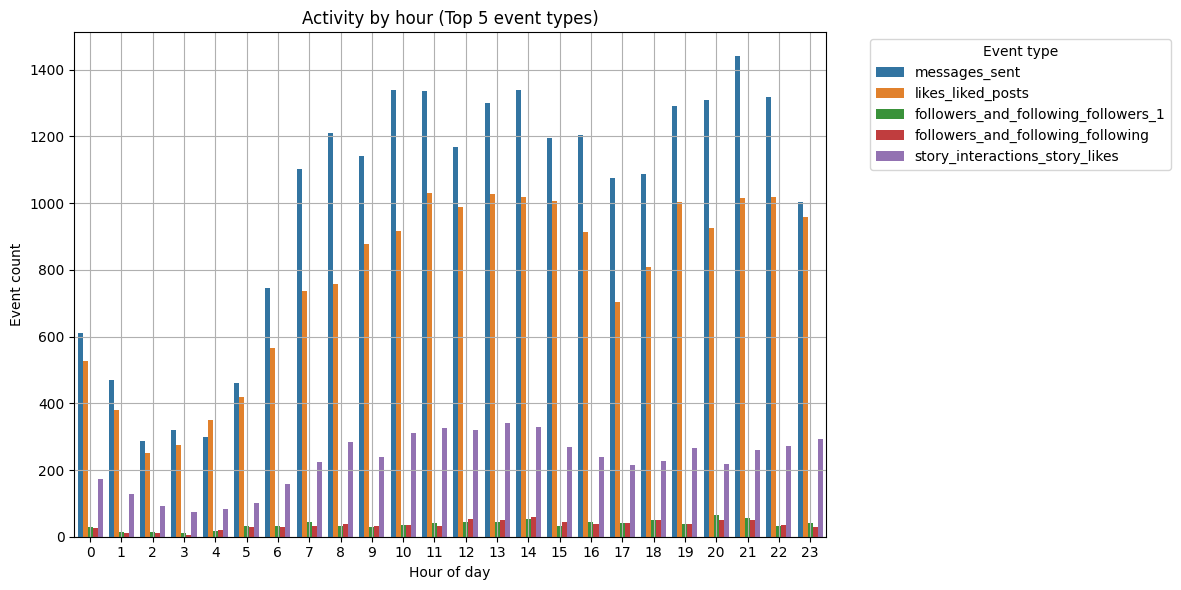

In [8]:
import seaborn as sns

# Obtener los 5 tipos de eventos más frecuentes
top_event_types = df["event_type"].value_counts().nlargest(5).index

# Filtrar el dataframe
df_top = df[df["event_type"].isin(top_event_types)].copy()

plt.figure(figsize=(12, 6))
sns.countplot(data=df_top, x="hour", hue="event_type", order=range(24))
plt.title("Activity by hour (Top 5 event types)")
plt.xlabel("Hour of day")
plt.ylabel("Event count")
plt.grid(True)
plt.legend(title="Event type", bbox_to_anchor=(1.05, 1), loc="upper left")
plt.tight_layout()
plt.show()



El análisis de los cinco tipos de eventos más comunes en Instagram revela que todos siguen una distribución horaria muy parecida, con dos picos principales de actividad: uno a media mañana (alrededor de las 11 h) y otro por la noche (entre las 20 h y 22 h). Esto sugiere que el comportamiento de uso es consistente independientemente del tipo de interacción, lo que refuerza la idea de que hay franjas horarias preferidas de uso general. Esta homogeneidad puede ser útil para diseñar una señal agregada de "uso horario", sin necesidad de tratar cada tipo de evento de forma separada en el modelo, al menos inicialmente

## ¿Actividad según día de la semana?

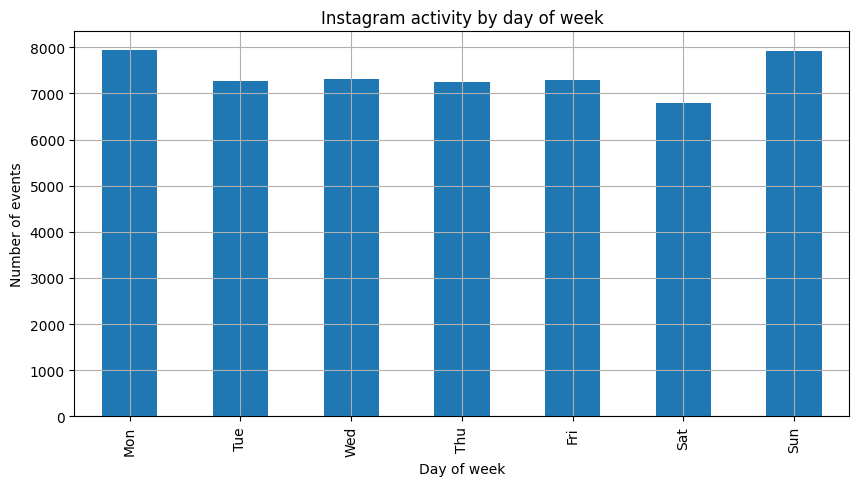

In [7]:
# Lunes=0, Domingo=6
df["weekday"] = df["timestamp"].dt.dayofweek
weekday_map = ["Mon", "Tue", "Wed", "Thu", "Fri", "Sat", "Sun"]

plt.figure(figsize=(10, 5))
df["weekday"].value_counts().sort_index().plot(kind="bar")
plt.title("Instagram activity by day of week")
plt.xlabel("Day of week")
plt.ylabel("Number of events")
plt.xticks(ticks=range(7), labels=weekday_map)
plt.grid(True)
plt.show()


La actividad en Instagram se mantiene estable durante todos los días de la semana, con pequeñas variaciones. Aunque hay un ligero repunte los domingos y lunes, y un descenso relativo los sábados, las diferencias son marginales. Esto sugiere un patrón de uso constante e independiente del día de la semana, lo que indica que el comportamiento en la plataforma no se ve condicionado significativamente por el calendario semanal. Esta regularidad puede simplificar el modelo, ya que no parece necesario incluir el día de la semana como variable predictiva clave, o al menos no como una señal fuerte.

## Evento predominante por día de la semana


C:\Users\AlmudenaBarreiroCarr\AppData\Local\Temp\ipykernel_21548\771728531.py:21: FutureWarning: The default of observed=False is deprecated and will be changed to True in a future version of pandas. Pass observed=False to retain current behavior or observed=True to adopt the future default and silence this warning.
  .groupby(['weekday', 'event_type'])


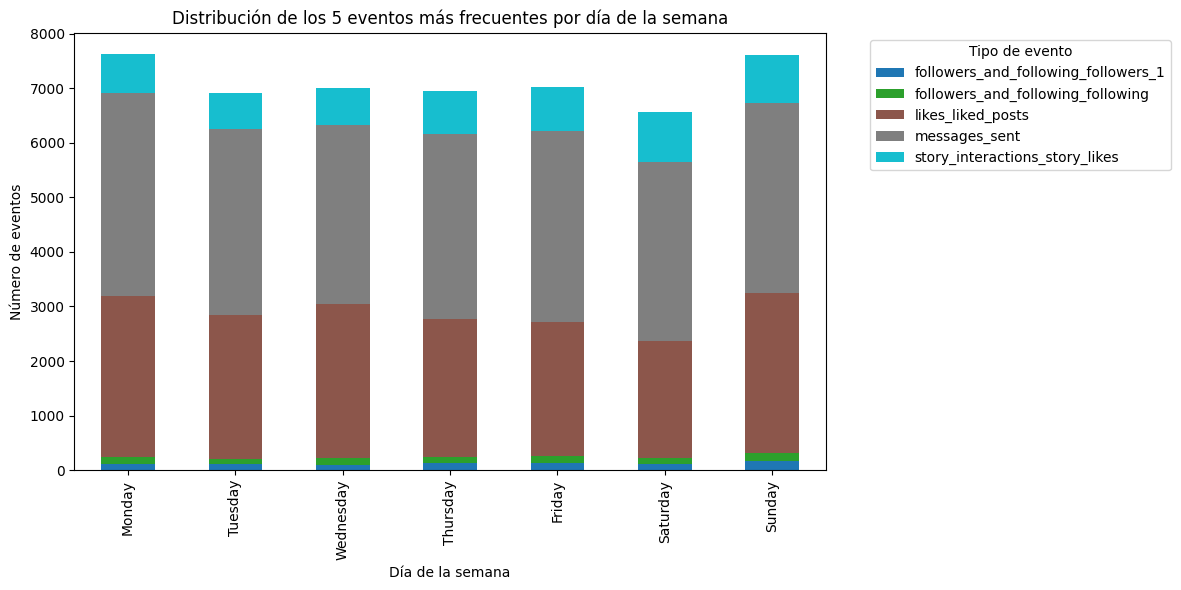

In [13]:
import pandas as pd
import matplotlib.pyplot as plt

# Asegúrate de tener estas columnas
df['timestamp'] = pd.to_datetime(df['timestamp'])
df['weekday'] = df['timestamp'].dt.day_name()

# Orden de los días
weekday_order = ['Monday', 'Tuesday', 'Wednesday', 'Thursday', 'Friday', 'Saturday', 'Sunday']
df['weekday'] = pd.Categorical(df['weekday'], categories=weekday_order, ordered=True)

# Obtener los 5 eventos más frecuentes en todo el dataset
top5_events = df['event_type'].value_counts().head(5).index.tolist()

# Filtrar solo esos eventos
df_top5 = df[df['event_type'].isin(top5_events)]

# Crear tabla pivote: filas = días, columnas = eventos, valores = conteo
pivot = (
    df_top5
    .groupby(['weekday', 'event_type'])
    .size()
    .unstack(fill_value=0)
    .loc[weekday_order]  # asegura orden de los días
)

# Graficar como barras apiladas
pivot.plot(kind='bar', stacked=True, figsize=(12, 6), colormap='tab10')
plt.title("Distribución de los 5 eventos más frecuentes por día de la semana")
plt.xlabel("Día de la semana")
plt.ylabel("Número de eventos")
plt.legend(title="Tipo de evento", bbox_to_anchor=(1.05, 1), loc='upper left')
plt.tight_layout()
plt.show()


C:\Users\AlmudenaBarreiroCarr\AppData\Local\Temp\ipykernel_21548\1219037123.py:30: UserWarning: Glyph 128202 (\N{BAR CHART}) missing from font(s) DejaVu Sans.
  plt.tight_layout()


<Figure size 1600x600 with 0 Axes>

h:\Mi unidad\pyCon_2025\Repo\instagram-behavior-analysis\.venv_instagram_project\Lib\site-packages\IPython\core\pylabtools.py:170: UserWarning: Glyph 128202 (\N{BAR CHART}) missing from font(s) DejaVu Sans.
  fig.canvas.print_figure(bytes_io, **kw)


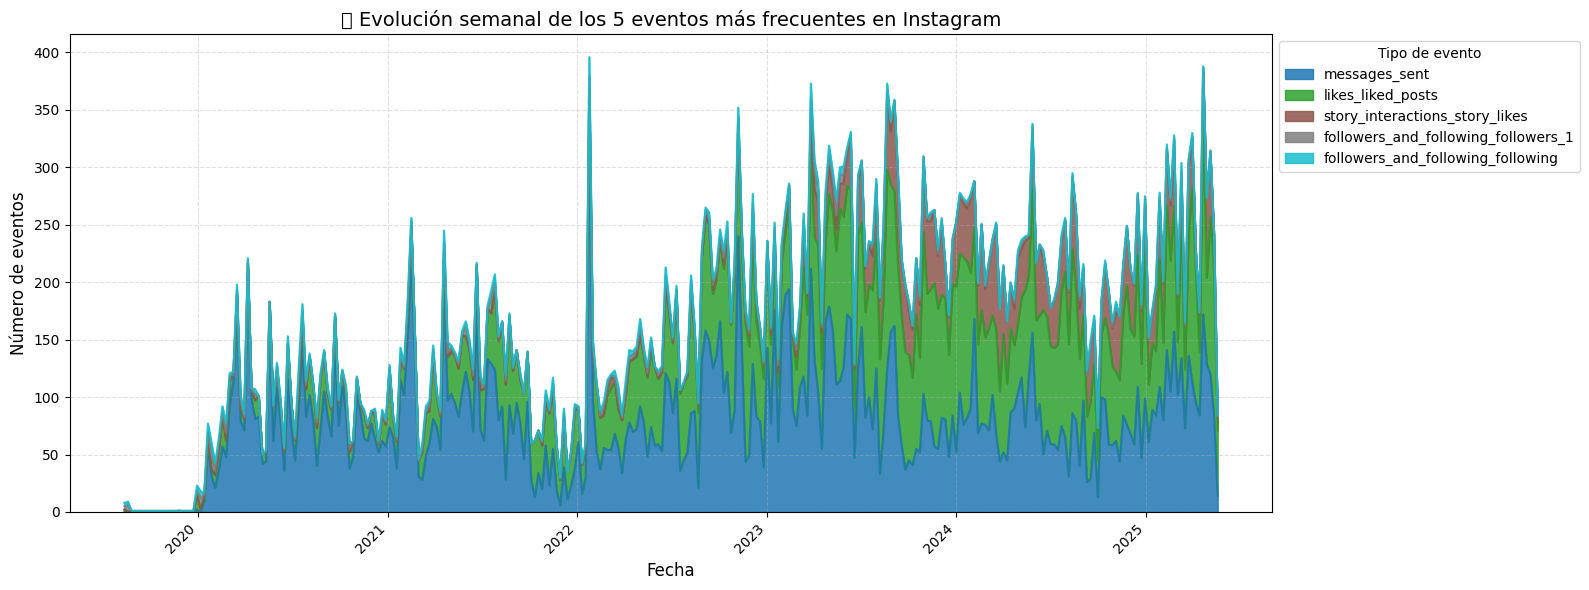

In [15]:
import pandas as pd
import matplotlib.pyplot as plt

# Agrupar y preparar los datos como antes
df['timestamp'] = pd.to_datetime(df['timestamp'])
df['week'] = df['timestamp'].dt.to_period('W').apply(lambda r: r.start_time)
top_5_events = df['event_type'].value_counts().nlargest(5).index
df_top5 = df[df['event_type'].isin(top_5_events)]
df_grouped = df_top5.groupby(['week', 'event_type']).size().unstack(fill_value=0)

# Reordenar columnas para que colores sean consistentes
df_grouped = df_grouped[top_5_events]

# 📈 Plot con mejoras de visibilidad
plt.figure(figsize=(16, 6))  # Aumentamos ancho

df_grouped.plot.area(
    stacked=True,
    figsize=(16, 6),
    alpha=0.85,
    colormap="tab10"
)

plt.title('📊 Evolución semanal de los 5 eventos más frecuentes en Instagram', fontsize=14)
plt.xlabel('Fecha', fontsize=12)
plt.ylabel('Número de eventos', fontsize=12)
plt.xticks(rotation=45)
plt.grid(True, linestyle='--', alpha=0.4)
plt.legend(title='Tipo de evento', loc='upper left', bbox_to_anchor=(1.0, 1.0))
plt.tight_layout()
plt.show()


## Hora del día con mayor actividad a lo largo del tiempo
Mostrar cómo la hora del día con mayor actividad cambia a lo largo del tiempo, usando agrupación diaria.

C:\Users\AlmudenaBarreiroCarr\AppData\Local\Temp\ipykernel_21548\1075697750.py:17: UserWarning: Glyph 9203 (\N{HOURGLASS WITH FLOWING SAND}) missing from font(s) DejaVu Sans.
  plt.tight_layout()
h:\Mi unidad\pyCon_2025\Repo\instagram-behavior-analysis\.venv_instagram_project\Lib\site-packages\IPython\core\pylabtools.py:170: UserWarning: Glyph 9203 (\N{HOURGLASS WITH FLOWING SAND}) missing from font(s) DejaVu Sans.
  fig.canvas.print_figure(bytes_io, **kw)


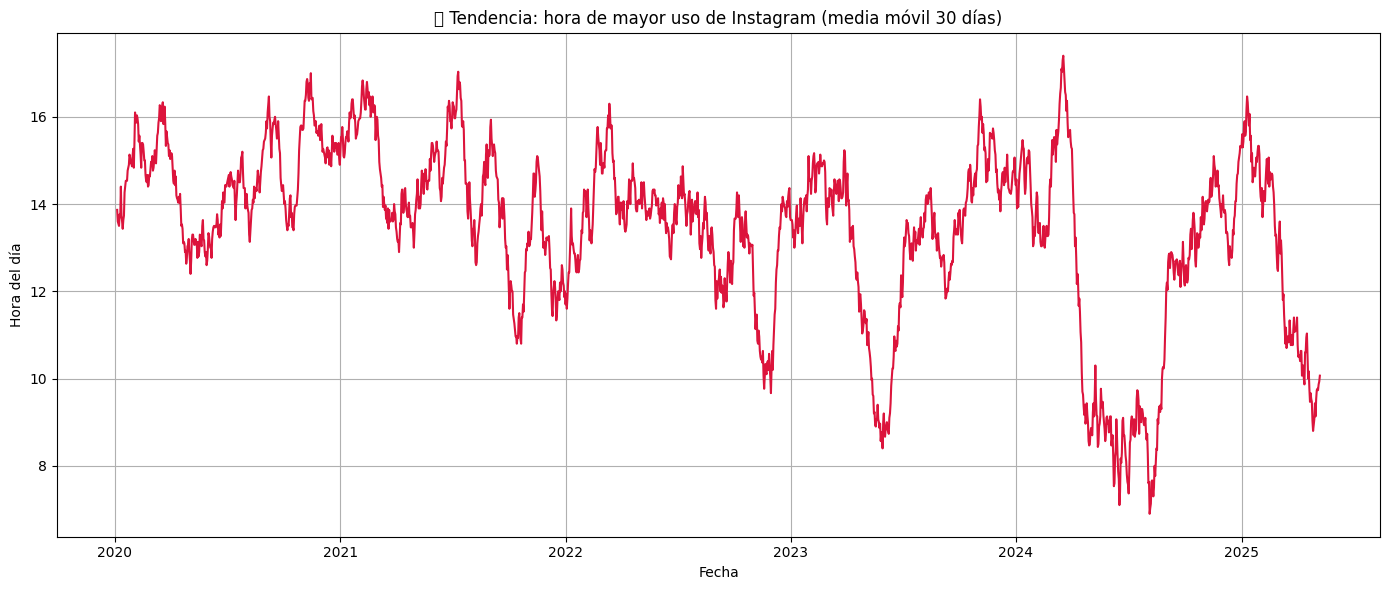

In [ ]:
# Calcular hora pico por día
df["hour"] = df["timestamp"].dt.hour
df["date"] = df["timestamp"].dt.date
peak_hour_per_day = df.groupby(["date", "hour"]).size().reset_index(name="count")
peak_hour = peak_hour_per_day.loc[peak_hour_per_day.groupby("date")["count"].idxmax()].sort_values("date")

# Suavizado con media móvil (por ejemplo, 30 días): hazme un promedio de las últimas 30 horas más activas por día para que no se vea tan caótico
peak_hour["hour_smooth"] = peak_hour["hour"].rolling(window=30, center=True).mean()

# Plot
plt.figure(figsize=(14, 6))
sns.lineplot(data=peak_hour, x="date", y="hour_smooth", color="crimson")
plt.title("Tendencia: hora de mayor uso de Instagram (media móvil 30 días)")
plt.xlabel("Fecha")
plt.ylabel("Hora del día")
plt.grid(True)
plt.tight_layout()
plt.show()


Este gráfico, que representa la hora de mayor uso diario de Instagram suavizada con una media móvil de 30 días, muestra una tendencia general descendente en el horario de uso a lo largo del tiempo. Aunque hay oscilaciones y picos evidentes, posiblemente relacionados con periodos vacacionales, cambios de rutina o eventos personales, el patrón dominante indica que cada vez tiendo a utilizar Instagram más temprano en el día. Esto podría reflejar cambios en tus hábitos, horarios de trabajo o incluso en la forma en que usas la aplicación (por ejemplo, más consumo matinal pasivo frente a interacción nocturna activa en el pasado).

## Boxplot de distribución por año
Esto muestra la variabilidad y mediana de las horas de uso por año

C:\Users\AlmudenaBarreiroCarr\AppData\Local\Temp\ipykernel_21548\2679230138.py:5: FutureWarning: 

Passing `palette` without assigning `hue` is deprecated and will be removed in v0.14.0. Assign the `x` variable to `hue` and set `legend=False` for the same effect.

  sns.boxplot(data=df, x="year", y="hour", palette="Set3")


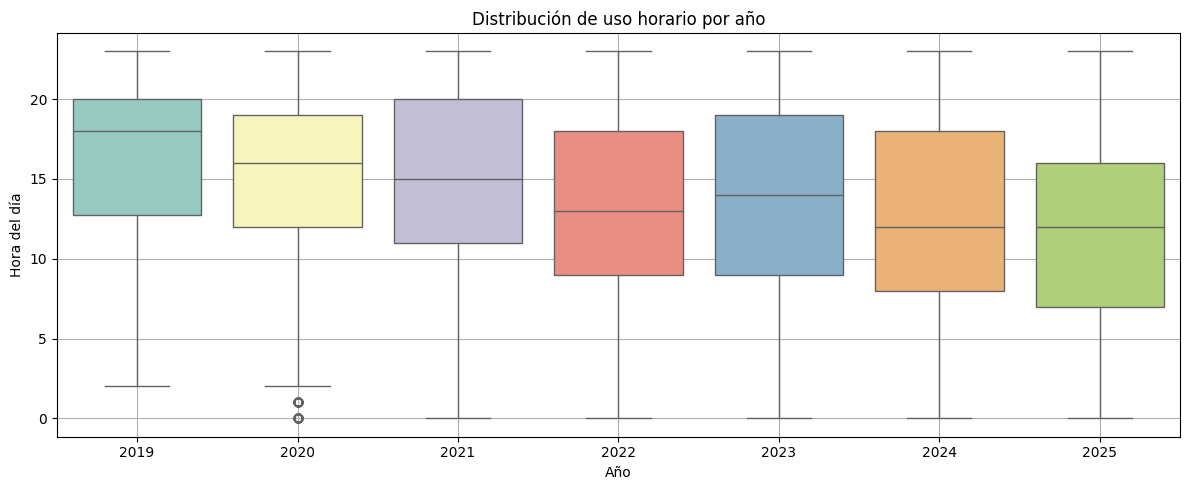

In [11]:
df["year"] = df["timestamp"].dt.year
df["hour"] = df["timestamp"].dt.hour

plt.figure(figsize=(12, 5))
sns.boxplot(data=df, x="year", y="hour", palette="Set3")
plt.title("Distribución de uso horario por año")
plt.ylabel("Hora del día")
plt.xlabel("Año")
plt.grid(True)
plt.tight_layout()
plt.show()


El boxplot por año confirma visualmente la tendencia a usar Instagram en horas más tempranas con el paso del tiempo. En 2019 y 2020, la mediana del horario de uso se situaba en torno a las 17–18 h, mientras que en 2024 y 2025 se ha desplazado claramente hacia las 12–13 h. Además, se aprecia cómo el rango intercuartílico también ha bajado, lo que indica que no solo se ha adelantado el uso promedio, sino que también se ha reducido la dispersión hacia horas más tardías

# Modelo
## Preparamos los datos

In [4]:
from data_loader import load_all_instagram_events

df = load_all_instagram_events(user_name="Almu", raw_data_path="../data/raw", inbox_path="../data/raw/inbox")

print(df['event_type'].unique().tolist())

Scanning 20 JSON files...
followers_and_following_followers_1: 873 timestamps extracted
followers_and_following_following: 828 timestamps extracted
followers_and_following_recent_follow_requests: 13 timestamps extracted
followers_and_following_recently_unfollowed_profiles: 3 timestamps extracted
likes_liked_comments: 563 timestamps extracted
likes_liked_posts: 18473 timestamps extracted
ads_and_topics_suggested_profiles_viewed: 324 timestamps extracted
ads_and_topics_videos_watched: 389 timestamps extracted
ads_and_topics_ads_clicked: 3 timestamps extracted
ads_and_topics_ads_viewed: 70 timestamps extracted
ads_and_topics_posts_viewed: 480 timestamps extracted
instagram_ads_and_businesses_advertisers_using_your_activity_or_information: 0 timestamps extracted
story_interactions_avatar_story_reactions: 4 timestamps extracted
story_interactions_countdowns: 5 timestamps extracted
story_interactions_polls: 137 timestamps extracted
story_interactions_questions: 2 timestamps extracted
story_i

In [5]:
from feature_engineering import prepare_time_series_for_nhits, aggregate_selected_event_types

df = load_all_instagram_events(user_name="Almu", raw_data_path="../data/raw", inbox_path="../data/raw/inbox")
print(df.head())
selected_event_types = [
    'followers_and_following_followers_1',
    'followers_and_following_following',
    'likes_liked_posts',
    'messages_sent',
    'likes_liked_comments',
    'story_interactions_story_likes',
    'ads_and_topics_posts_viewed',
    'ads_and_topics_videos_watched',
    'ads_and_topics_ads_viewed'
]
df_agg = aggregate_selected_event_types(df, selected_event_types, freq='H')
signals = [col for col in df_agg.columns if col != 'timestamp']

ts_df = prepare_time_series_for_nhits(df_agg, signals, freq='H')  # mismo freq que antes

print(ts_df.head())
ts_df

Scanning 20 JSON files...
followers_and_following_followers_1: 873 timestamps extracted
followers_and_following_following: 828 timestamps extracted
followers_and_following_recent_follow_requests: 13 timestamps extracted
followers_and_following_recently_unfollowed_profiles: 3 timestamps extracted
likes_liked_comments: 563 timestamps extracted
likes_liked_posts: 18473 timestamps extracted
ads_and_topics_suggested_profiles_viewed: 324 timestamps extracted
ads_and_topics_videos_watched: 389 timestamps extracted
ads_and_topics_ads_clicked: 3 timestamps extracted
ads_and_topics_ads_viewed: 70 timestamps extracted
ads_and_topics_posts_viewed: 480 timestamps extracted
instagram_ads_and_businesses_advertisers_using_your_activity_or_information: 0 timestamps extracted
story_interactions_avatar_story_reactions: 4 timestamps extracted
story_interactions_countdowns: 5 timestamps extracted
story_interactions_polls: 137 timestamps extracted
story_interactions_questions: 2 timestamps extracted
story_i

h:\Mi unidad\pyCon_2025\Repo\instagram-behavior-analysis\src\feature_engineering.py:23: FutureWarning: 'H' is deprecated and will be removed in a future version, please use 'h' instead.
  .resample(freq)['count']
h:\Mi unidad\pyCon_2025\Repo\instagram-behavior-analysis\src\feature_engineering.py:38: FutureWarning: 'H' is deprecated and will be removed in a future version, please use 'h' instead.
  df = df.set_index('timestamp').resample(freq).sum().reset_index()


event_type                  ds    y                  unique_id
0          2019-08-17 20:00:00  0.0  ads_and_topics_ads_viewed
1          2019-08-17 21:00:00  0.0  ads_and_topics_ads_viewed
2          2019-08-17 22:00:00  0.0  ads_and_topics_ads_viewed
3          2019-08-17 23:00:00  0.0  ads_and_topics_ads_viewed
4          2019-08-18 00:00:00  0.0  ads_and_topics_ads_viewed


event_type,ds,y,unique_id
0,2019-08-17 20:00:00,0.0,ads_and_topics_ads_viewed
1,2019-08-17 21:00:00,0.0,ads_and_topics_ads_viewed
2,2019-08-17 22:00:00,0.0,ads_and_topics_ads_viewed
3,2019-08-17 23:00:00,0.0,ads_and_topics_ads_viewed
4,2019-08-18 00:00:00,0.0,ads_and_topics_ads_viewed
...,...,...,...
454549,2025-05-22 01:00:00,0.0,story_interactions_story_likes
454550,2025-05-22 02:00:00,0.0,story_interactions_story_likes
454551,2025-05-22 03:00:00,0.0,story_interactions_story_likes
454552,2025-05-22 04:00:00,1.0,story_interactions_story_likes


In [14]:
total_activity = ts_df.groupby('ds', as_index=False)['y'].sum()
total_activity

,ds,y
0,2019-08-17 20:00:00,4.0
1,2019-08-17 21:00:00,1.0
2,2019-08-17 22:00:00,0.0
3,2019-08-17 23:00:00,0.0
4,2019-08-18 00:00:00,0.0
...,...,...
50501,2025-05-22 01:00:00,3.0
50502,2025-05-22 02:00:00,0.0
50503,2025-05-22 03:00:00,0.0
50504,2025-05-22 04:00:00,5.0


In [ ]:
total_activity.rename(columns={'y': 'total_events'})
total_activity['unique_id'] = 'total_events'
total_activity

In [12]:
# 1. Asegúrate de que 'ds' es datetime
ts_df['ds'] = pd.to_datetime(ts_df['ds'])

# 2. Crear nueva columna 'date' directamente
ts_df['date'] = ts_df['ds'].dt.date

# 3. Agrupar por 'date' y sumar
total_daily_activity = (
    ts_df.groupby('date', as_index=False)['y']
    .sum()
    .rename(columns={'y': 'total_events'})
)
total_daily_activity

,date,total_events
0,2019-08-17,5.0
1,2019-08-18,3.0
2,2019-08-19,0.0
3,2019-08-20,3.0
4,2019-08-21,3.0
...,...,...
2101,2025-05-18,144.0
2102,2025-05-19,138.0
2103,2025-05-20,255.0
2104,2025-05-21,205.0


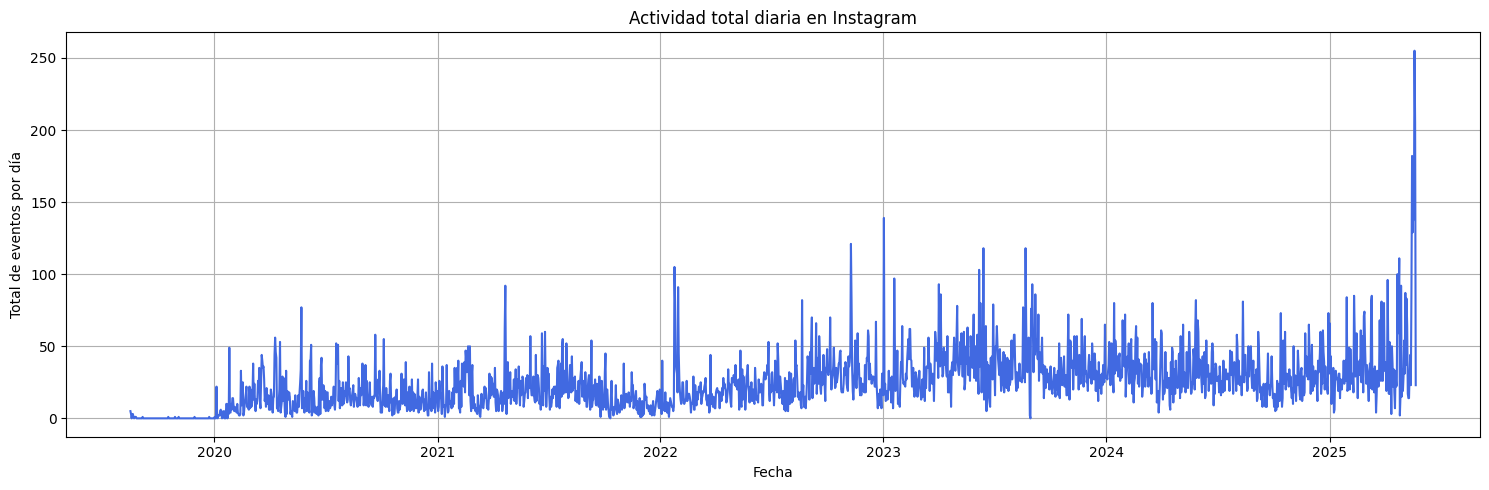

In [ ]:
import matplotlib.pyplot as plt

plt.figure(figsize=(15, 5))
plt.plot(total_daily_activity['date'], total_daily_activity['total_events'], color='royalblue')
plt.title('Actividad total diaria en Instagram')
plt.xlabel('Fecha')
plt.ylabel('Total de eventos por día')
plt.grid(True)
plt.tight_layout()
plt.show()



Parece que los datos limpios para el modelo están bien

In [6]:
from forecasting_model import train_and_forecast_nhits_daily_2025

nf, forecast_df, true_2025_df = train_and_forecast_nhits_daily_2025(ts_df)


h:\Mi unidad\pyCon_2025\Repo\instagram-behavior-analysis\.venv_instagram_project\Lib\site-packages\tqdm\auto.py:21: TqdmWarning: IProgress not found. Please update jupyter and ipywidgets. See https://ipywidgets.readthedocs.io/en/stable/user_install.html
  from .autonotebook import tqdm as notebook_tqdm
2025-09-22 20:35:16,735	INFO util.py:154 -- Missing packages: ['ipywidgets']. Run `pip install -U ipywidgets`, then restart the notebook server for rich notebook output.
2025-09-22 20:35:19,244	INFO util.py:154 -- Missing packages: ['ipywidgets']. Run `pip install -U ipywidgets`, then restart the notebook server for rich notebook output.
Seed set to 1
h:\Mi unidad\pyCon_2025\Repo\instagram-behavior-analysis\.venv_instagram_project\Lib\site-packages\neuralforecast\common\_base_model.py:537: UserWarning: val_check_steps is greater than max_steps, setting val_check_steps to max_steps.
  warnings.warn(
GPU available: False, used: False
TPU available: False, using: 0 TPU cores
HPU available: 

Epoch 4: 100%|██████████| 1/1 [00:00<00:00,  3.41it/s, v_num=11, train_loss_step=13.90, train_loss_epoch=13.90]

`Trainer.fit` stopped: `max_steps=5` reached.


Epoch 4: 100%|██████████| 1/1 [00:00<00:00,  3.26it/s, v_num=11, train_loss_step=13.90, train_loss_epoch=13.90]


GPU available: False, used: False
TPU available: False, using: 0 TPU cores
HPU available: False, using: 0 HPUs


Predicting DataLoader 0: 100%|██████████| 1/1 [00:00<00:00, 76.93it/s]


In [7]:
forecast_df

,unique_id,ds,NHITS
0,total,2025-01-01,29.357748
1,total,2025-01-02,28.753803
2,total,2025-01-03,29.208677
3,total,2025-01-04,27.389107
4,total,2025-01-05,27.930717
...,...,...,...
137,total,2025-05-18,27.793255
138,total,2025-05-19,27.920153
139,total,2025-05-20,29.726685
140,total,2025-05-21,29.281675


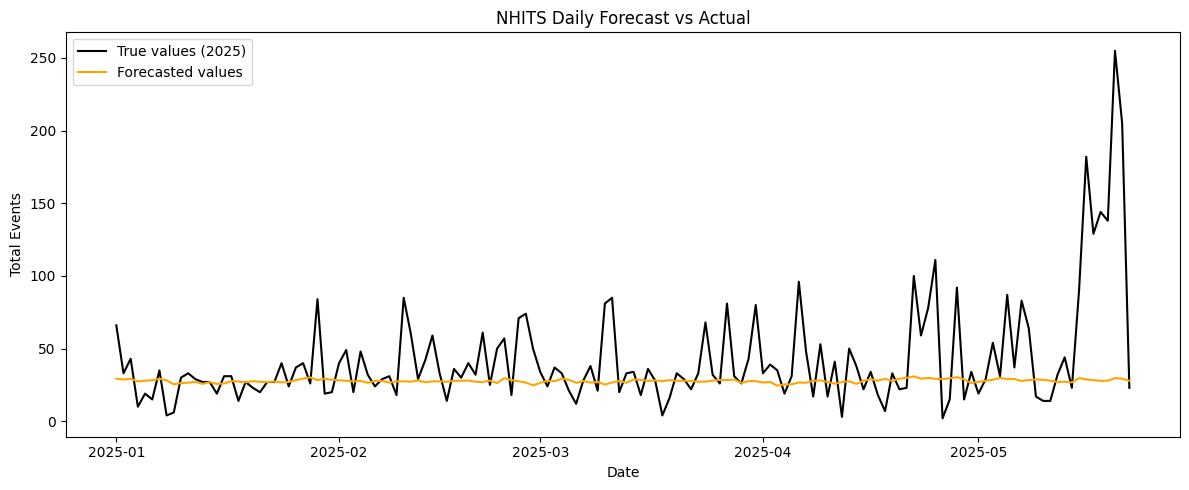

,unique_id,ds,NHITS
0,total,2025-01-01,29.357748
1,total,2025-01-02,28.753803
2,total,2025-01-03,29.208677
3,total,2025-01-04,27.389107
4,total,2025-01-05,27.930717
...,...,...,...
137,total,2025-05-18,27.793255
138,total,2025-05-19,27.920153
139,total,2025-05-20,29.726685
140,total,2025-05-21,29.281675


In [8]:
import matplotlib.pyplot as plt
import numpy as np
import pandas as pd

# Unir las predicciones y los valores reales por la columna 'ds'
merged = pd.merge(forecast_df, true_2025_df, on='ds', how='inner')



# Graficar comparación
plt.figure(figsize=(12, 5))
plt.plot(merged['ds'], merged['y'], label='True values (2025)', color='black')
plt.plot(merged['ds'], merged['NHITS'], label='Forecasted values', color='orange')
plt.title("NHITS Daily Forecast vs Actual")
plt.xlabel("Date")
plt.ylabel("Total Events")
plt.legend()
plt.tight_layout()
plt.show()
forecast_df